# 11. Аудит остаточных форматов METAR

## 1. Область и способ проверки

Проверены все 2425 уникальных сообщений с замечаниями в полном погодном
наборе. Отбор задан прежним результатом декодера, а не исходом посадки.
Декодер и проверка основного префикса повторно воспроизведены для каждого
сообщения. Исходные тексты, значения и модельная числовая копия не изменяются.

Основная категория назначена по заранее указанному приоритету наблюдаемых
форматов: конвективный тип без количества/высоты, девять слешей, шесть слешей,
расхождение по явлениям, хвост после QNH, видимость, ветер, облачность, ошибка
строгого парсера, прочее. Это организация аудита, а не установленная причина
ошибки станции. Вторичные флаги пересекаются; основные категории — нет.


In [1]:
from pathlib import Path
import hashlib, json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, HTML
from html import escape
from cycler import cycler

BASE = Path.cwd().resolve()
while not (BASE / 'reports/03_pilot_manifest.json').exists():
    if BASE == BASE.parent:
        raise FileNotFoundError('Не найдена папка europe/weather с выполненным пилотом')
    BASE = BASE.parent
PROJECT = BASE.parents[1]
R, F, DATA = BASE / 'reports', BASE / 'figures', BASE / 'data'
F.mkdir(exist_ok=True)
sys.path.insert(0, str(BASE / 'scripts'))
manifest = json.loads((R / '03_pilot_manifest.json').read_text(encoding='utf8'))
def sha(path):
    with path.open('rb') as stream:
        return hashlib.file_digest(stream, 'sha256').hexdigest()
assert sha(PROJECT / 'europe/data/analytical/06_05_cases_excluded.parquet') == manifest['input_sha256']
for source in manifest['downloads']:
    path = DATA / 'raw' / f"{source['airport']}_{source['month']}.csv"
    assert sha(path) == source['sha256']

GREEN, CORAL, LIGHT_GREEN, LIGHT_CORAL = '#00897B', '#D65A4A', '#80CBC4', '#E69A90'
plt.rcParams.update({'figure.dpi':120, 'font.size':11, 'axes.spines.top':False,
    'axes.spines.right':False, 'axes.grid':True, 'grid.alpha':.16,
    'axes.prop_cycle':cycler(color=[CORAL, GREEN, LIGHT_CORAL, LIGHT_GREEN])})
pd.set_option('display.max_columns', 20)
pd.set_option('display.max_rows', 30)
pd.set_option('display.max_colwidth', 100)
def save(name):
    plt.tight_layout()
    for ext in ['png', 'svg']:
        plt.savefig(F / f'{name}.{ext}', bbox_inches='tight')
    plt.show()
def readable_table(frame):
    html = frame.to_html(index=False, escape=True)
    display(HTML('<div style="max-width:100%;overflow:auto">' + html + '</div>'))


In [2]:
audit=json.loads((R/'19_residual_format_audit.json').read_text(encoding='utf8'))
cases=pd.read_csv(R/'19_residual_format_cases.csv',keep_default_na=False)
groups=pd.read_csv(R/'19_residual_format_groups.csv')
issues=pd.read_csv(R/'19_residual_issue_counts.csv')
unparsed=pd.read_csv(R/'19_residual_unparsed_groups.csv',keep_default_na=False)
assert cases.metar_id.is_unique and len(cases)==groups.messages.sum()==2425
assert audit['all_saved_issue_strings_reproduced'] and audit['all_saved_core_flags_reproduced']
assert sha(R/'12_full_residuals.csv')==audit['source_sha256']
assert sha(BASE/'scripts/decode_metar.py')==audit['decoder_sha256']
assert sha(BASE/'scripts/audit_residual_formats.py')==audit['audit_script_sha256']
display(pd.DataFrame([audit]))
readable_table(groups)
readable_table(issues)


,messages,exclusive_category_total,all_residuals_replayed,all_saved_issue_strings_reproduced,all_saved_core_flags_reproduced,source_sha256,decoder_sha256,audit_script_sha256,decoder_changed,weather_features_changed,rows_deleted,training_executed,links_scope,format_flags_overlap,primary_categories_exclusive,matched_60min_rows,matched_60min_go_arounds,matched_60min_core_validated_rows
0,2425,2425,True,True,True,fb5a917bd8dfc59106dc1645d308315a81690933063a3da3b0a2e0eba3d51803,6c1fc46f433a30a870d48d20c0c0e9c7d342e40a8612194a412ba1b618faf9bb,6b9d916c0a6ba280ae99028ef38ec7d6f98aba592535eca77188938e094b1886,False,False,0,False,all baseline statuses; no 60-minute filter in source residual aggregate,True,True,6808,37,2429


primary_category,messages,core_validated_messages,linked_rows,linked_go_arounds,matched_60min_rows,matched_60min_go_arounds
convective_type_without_amount_height,867,0,1204,7,1204,7
strict_parser_error,578,515,2112,15,2083,15
nine_slash_cloud_placeholder,472,0,1868,5,1868,5
weather_parser_disagreement,180,0,413,7,413,7
unclassified_tail_after_qnh,167,167,597,3,597,3
visibility_outside_current_scope,144,0,553,0,553,0
other_issue_requires_individual_review,11,0,71,0,71,0
other_cloud_parser_disagreement,4,0,19,0,19,0
six_slash_placeholder,2,0,0,0,0,0


issue,messages,linked_rows
parser_value_disagreement_cloud_layers,1327,2906
parser_error,822,3122
parser_value_disagreement_weather,180,413
unclassified_weather_after_qnh,167,597
visibility_format_outside_pilot_scope,146,553
wind_group_missing_or_multiple,29,162
qnh_group_missing_or_multiple,26,111
parser_value_disagreement_qnh,2,27
cavok_with_explicit_weather_or_cloud,1,5


## 2. Частота форматов и воздействие на аналитические строки

Число сообщений и число связанных посадок — разные единицы. Основной
сценарий: предшествующее сообщение до 60 минут, задержка 0 минут, COR сохранены.
Связи пересчитаны по полным файлам признаков. Более старые сообщения не
включены в столбцы `matched_60min_*`; исходные `linked_*` сохраняют все статусы.


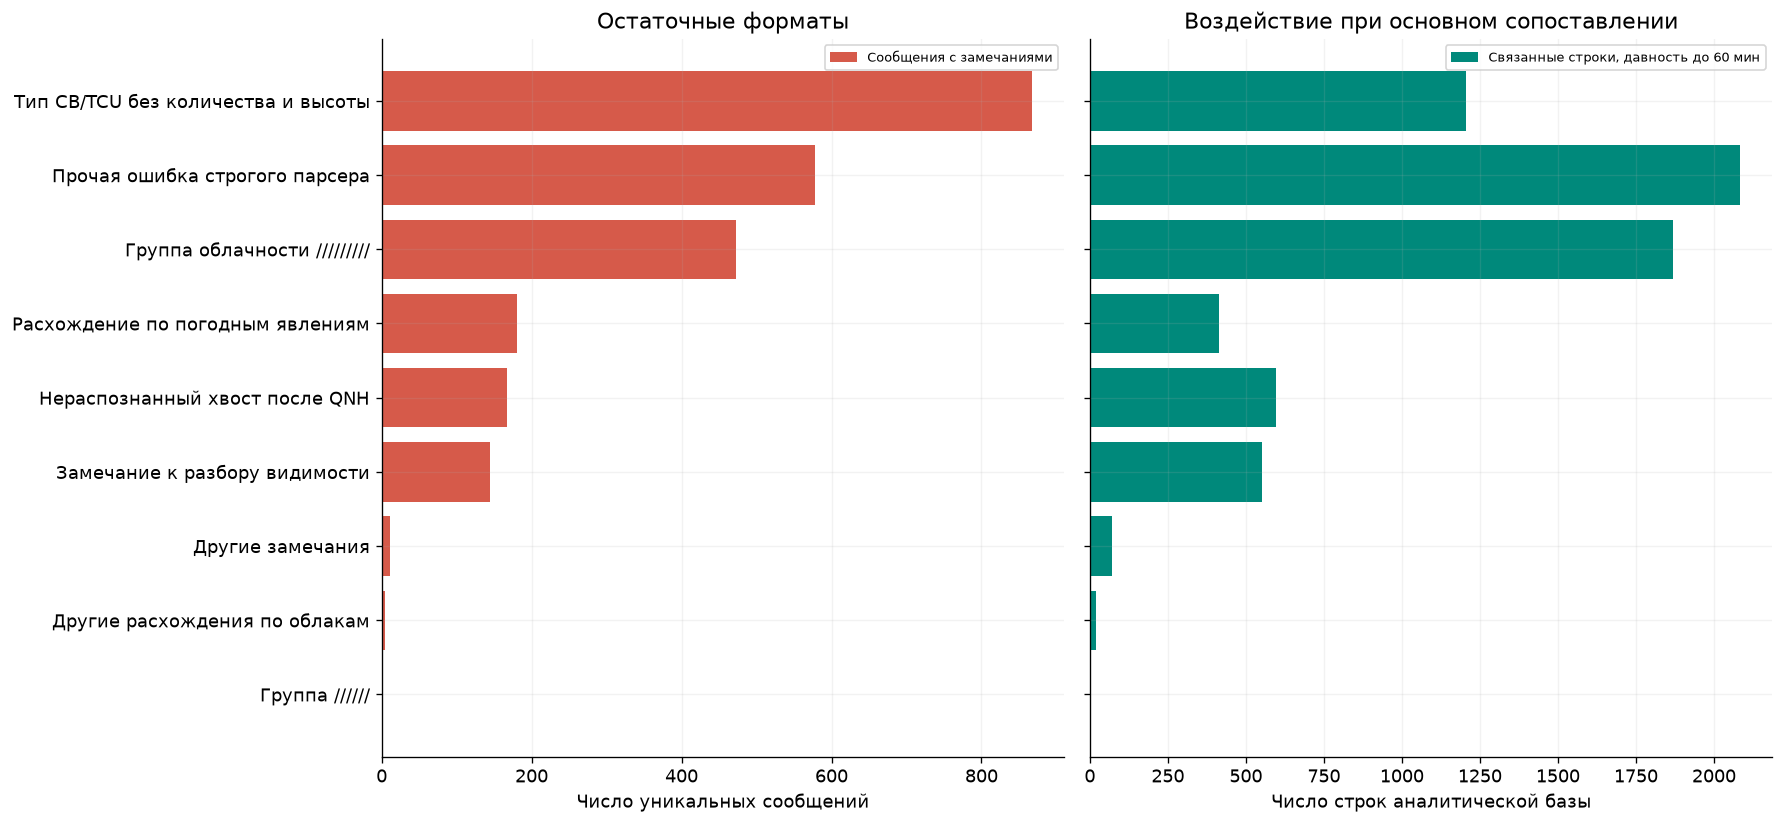

primary_category,core_validated,messages,matched_60min_rows,matched_60min_go_arounds
convective_type_without_amount_height,False,867,1204,7
nine_slash_cloud_placeholder,False,472,1868,5
other_cloud_parser_disagreement,False,4,19,0
other_issue_requires_individual_review,False,11,71,0
six_slash_placeholder,False,2,0,0
strict_parser_error,False,63,251,0
strict_parser_error,True,515,1832,15
unclassified_tail_after_qnh,True,167,597,3
visibility_outside_current_scope,False,144,553,0
weather_parser_disagreement,False,180,413,7


In [3]:
names={
'convective_type_without_amount_height':'Тип CB/TCU без количества и высоты',
'nine_slash_cloud_placeholder':'Группа облачности /////////',
'six_slash_placeholder':'Группа //////',
'weather_parser_disagreement':'Расхождение по погодным явлениям',
'unclassified_tail_after_qnh':'Нераспознанный хвост после QNH',
'visibility_outside_current_scope':'Замечание к разбору видимости',
'wind_missing_or_multiple':'Замечание к группе ветра',
'other_cloud_parser_disagreement':'Другие расхождения по облакам',
'strict_parser_error':'Прочая ошибка строгого парсера',
'other_issue_requires_individual_review':'Другие замечания'}
ordered=groups.sort_values('messages')
fig,axes=plt.subplots(1,2,figsize=(15,7),sharey=True)
y=np.arange(len(ordered))
axes[0].barh(y,ordered.messages,color=CORAL,label='Сообщения с замечаниями')
axes[1].barh(y,ordered.matched_60min_rows,color=GREEN,label='Связанные строки, давность до 60 мин')
axes[0].set_yticks(y,ordered.primary_category.map(names))
axes[0].set(xlabel='Число уникальных сообщений',title='Остаточные форматы')
axes[1].set(xlabel='Число строк аналитической базы',title='Воздействие при основном сопоставлении')
for ax in axes:ax.legend(fontsize=8)
save('29_residual_formats_and_links')
readable_table(cases.groupby(['primary_category','core_validated']).agg(messages=('metar_id','size'),
    matched_60min_rows=('matched_60min_rows','sum'),matched_60min_go_arounds=('matched_60min_go_arounds','sum')).reset_index())


## 3. Облачные группы с отсутствующими компонентами

В [руководстве Météo-France 2021, печатная страница 17](https://meteofrance.fr/sites/meteofrance.fr/files/files/editorial/guide_aviation_2021.pdf)
группы `///CB` и `///TCU` обозначают обнаруженный тип конвективного облака при
неизвестных количестве и высоте. Это не отсутствие конвекции и не нулевая
высота. В нашем регулярном выражении группа требует отдельные количество
и высоту, поэтому короткая форма не распознается как слой: признаки типа
могут ошибочно оставаться False. Подтверждение кода не подтверждает измерение
в конкретном сообщении и его историческую доступность.

Группа `/////////` встречается в 472 остаточных сообщениях. Ручной разбор
сохраняет неизвестные количество, высоту и тип, но количество слоев отличается
от python-metar. В отличие от короткого CB/TCU, это расхождение представления
пропусков. Оно не разрешает превращать неизвестную облачность в ясное небо.


,Сообщений с коротким CB/TCU,"Короткая TCU есть, декодированный флаг False","Короткая CB есть, декодированный флаг False"
0,867,448,419


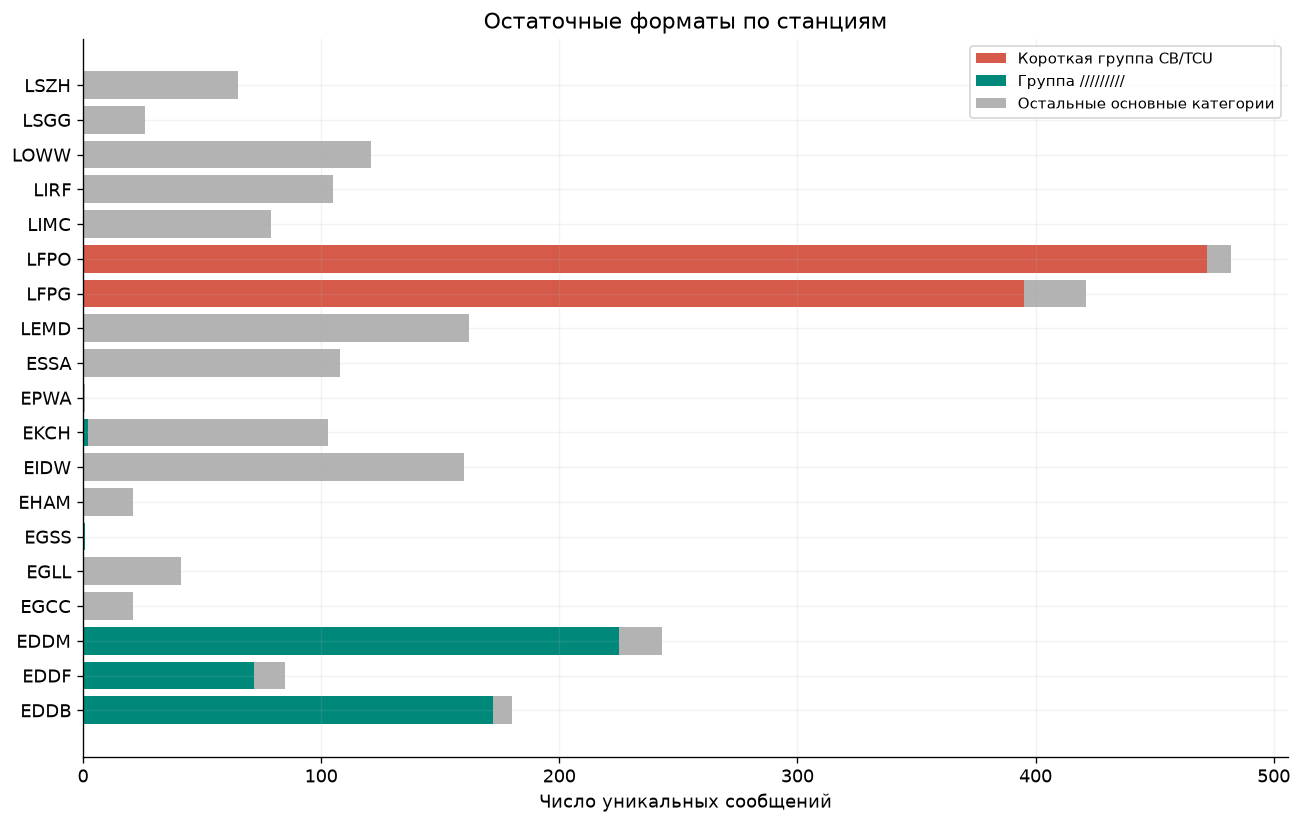

In [4]:
conv=cases.loc[cases.primary_category.eq('convective_type_without_amount_height')].copy()
conv['raw_tcu']=conv.observed_text.str.split().apply(lambda ts:'///TCU' in ts)
conv['raw_cb']=conv.observed_text.str.split().apply(lambda ts:'///CB' in ts)
display(pd.DataFrame([{
    'Сообщений с коротким CB/TCU':len(conv),
    'Короткая TCU есть, декодированный флаг False':int((conv.raw_tcu & ~conv.towering_cumulus_reported).sum()),
    'Короткая CB есть, декодированный флаг False':int((conv.raw_cb & ~conv.cumulonimbus_reported).sum())}]))
station=cases.groupby(['station','primary_category']).size().unstack(fill_value=0)
typed=station.get('convective_type_without_amount_height',pd.Series(0,index=station.index))
missing=station.get('nine_slash_cloud_placeholder',pd.Series(0,index=station.index))
other=station.sum(axis=1)-typed-missing
fig,ax=plt.subplots(figsize=(11,7))
ax.barh(station.index,typed,color=CORAL,label='Короткая группа CB/TCU')
ax.barh(station.index,missing,left=typed,color=GREEN,label='Группа /////////')
ax.barh(station.index,other,left=typed+missing,color='0.7',label='Остальные основные категории')
ax.set(xlabel='Число уникальных сообщений',title='Остаточные форматы по станциям')
ax.legend(fontsize=9)
save('30_residual_formats_by_station')


## 4. Остальные группы и исходные примеры

Ошибки строгого парсера группируются по нераспознанным фрагментам, а не
полным строкам ошибок с разным временем. Среди примеров встречаются группы
состояния ВПП, RE//, разделенные пробелами обозначения сдвига ветра,
нетипичные погодные сочетания и хвосты с похожими на TREND обозначениями.
Такие фрагменты требуют индивидуального правила; автоматическое исправление
порядка символов и добавление BECMG/TEMPO не выполнены.

Замечание к видимости не всегда означает неизвестную видимость: нетипичная
группа изменения ветра перед видимостью может нарушить позиционный разбор.
Дефект представления, неподдержанный формат и вероятное повреждение текста
нельзя объединять в одно утверждение об ошибке источника.


In [5]:
readable_table(unparsed.head(30))
for category in groups.primary_category:
    display(Markdown('### '+names[category]))
    part=cases.loc[cases.primary_category.eq(category)].sort_values(['station','metar_utc','metar_id'])
    readable_table(part.head(5)[['station','metar_utc','metar','decode_issues','unparsed_groups',
        'core_validated','matched_60min_rows','matched_60min_go_arounds']])
small=cases.loc[cases.primary_category.isin(['other_issue_requires_individual_review','other_cloud_parser_disagreement','six_slash_placeholder'])]
display(Markdown('### Все случаи трех малых категорий'))
readable_table(small[['station','metar_utc','metar','decode_issues']])


unparsed_groups,messages,matched_60min_rows
R88/99,47,0
R88/29,41,32
RE//,37,375
R88/D,35,210
R01L/CLSD,21,18
R99/99,17,0
R08/N,16,16
R04/29,15,25
RKC/,14,54
BKN015,12,24


### Тип CB/TCU без количества и высоты

station,metar_utc,metar,decode_issues,unparsed_groups,core_validated,matched_60min_rows,matched_60min_go_arounds
LFPG,2019-09-24 07:30:00+00:00,LFPG 240730Z AUTO 15024KT 9999 ///TCU 16/12 Q1006 TEMPO 22015G25KT 2000 RA OVC008,parser_value_disagreement_cloud_layers,,False,12,0
LFPG,2019-09-24 08:30:00+00:00,LFPG 240830Z AUTO 19015KT 9999 -RA BKN017/// OVC110/// ///TCU 16/13 Q1009 TEMPO 22015G25KT 2000 RA OVC008,parser_value_disagreement_cloud_layers,,False,17,0
LFPG,2019-09-24 09:30:00+00:00,LFPG 240930Z AUTO 17011KT 9999 OVC016/// ///TCU 16/13 Q1008 TEMPO 22015G25KT 2000 RA OVC008,parser_value_disagreement_cloud_layers,,False,25,0
LFPG,2019-09-24 11:30:00+00:00,LFPG 241130Z AUTO 16012G28KT 140V280 7000 -RA OVC006/// ///TCU 16/15 Q1006 TEMPO 2000 RA BKN005,parser_value_disagreement_cloud_layers,,False,21,0
LFPG,2019-09-24 16:00:00+00:00,LFPG 241600Z AUTO 23007KT 9999 FEW019/// SCT044/// ///CB 20/15 Q1005 TEMPO 22015G30KT 3000 TSRA,parser_value_disagreement_cloud_layers,,False,12,0


### Прочая ошибка строгого парсера

station,metar_utc,metar,decode_issues,unparsed_groups,core_validated,matched_60min_rows,matched_60min_go_arounds
EDDB,2021-01-25 03:20:00+00:00,EDDB 250320Z 28007KT 7000 BKN007 00/M01 Q0999 R88/D TEMPO 4500 BR BKN004,parser_error,R88/D,True,0,0
EDDB,2021-01-25 03:50:00+00:00,EDDB 250350Z 27005KT 9000 BKN008 00/M01 Q0999 R88/D TEMPO 4500 BR BKN004,parser_error,R88/D,True,0,0
EDDB,2021-01-25 04:20:00+00:00,COR EDDB 250420Z 26005KT 9999 BKN011 00/M00 Q0999 R88/D BECMG BKN015,parser_error,R88/D,True,0,0
EDDB,2021-01-25 04:50:00+00:00,EDDB 250450Z 27003KT 9999 FEW015 BKN028 M00/M01 Q1000 R88/D NOSIG,parser_error,R88/D,True,0,0
EDDB,2022-10-11 08:50:00+00:00,EDDB 110850Z AUTO 26005KT 200V300 9999 FEW011 12/08 Q1025 RE// NOSIG,parser_error,RE//,True,6,0


...

station,metar_utc,metar,decode_issues,unparsed_groups,core_validated,matched_60min_rows,matched_60min_go_arounds
EIDW,2022-09-11 07:00:00+00:00,EIDW 110700Z 12005KT 100V170 9999 SCT0600 BKN100 15/13 Q1015 NOSIG,parser_value_disagreement_cloud_layers,,False,4,0
EIDW,2022-09-11 07:30:00+00:00,EIDW 110730Z 12005KT 100V170 9999 SCT0600 BKN100 15/13 Q1015 NOSIG,parser_value_disagreement_cloud_layers,,False,9,0
ESSA,2020-04-02 17:20:00+00:00,ESSA 021720Z 25018KT 8000 -SHRASN BKN017CB OVC3700 01/M01 Q0976 R01L/29//95 R01R/29//95 R08/29//95 TEMPO 4000 SHRASN BKN020CB,parser_value_disagreement_cloud_layers,,False,1,0
LIMC,2019-10-24 05:50:00+00:00,LIMC 240550Z 05003KT 360V080 3500 RA BR BKN015 OVC05 Q1016,parser_value_disagreement_cloud_layers,,False,5,0


### Группа //////

station,metar_utc,metar,decode_issues,unparsed_groups,core_validated,matched_60min_rows,matched_60min_go_arounds
LSGG,2019-03-27 22:50:00+00:00,LSGG 272250Z AUTO /////KT ///V/// //// // ////// ///// Q//// NOSIG,parser_error;visibility_format_outside_pilot_scope,///V///,False,0,0
LSGG,2019-03-27 23:20:00+00:00,LSGG 272320Z AUTO /////KT ///V/// //// // ////// ///// Q//// NOSIG,parser_error;visibility_format_outside_pilot_scope,///V///,False,0,0


### Все случаи трех малых категорий

station,metar_utc,metar,decode_issues
EGCC,2019-12-18 18:50:00+00:00,EGCC 181850Z 14012G22KT 080V200 9999 -SHRA BKN020TCU 08/06 TEMPO RA Q0998,qnh_group_missing_or_multiple
EGLL,2021-03-25 19:50:00+00:00,COR EGLL 251950Z AUTO 21010KT 190V260 9999 SCT019 10/07 NOSIG,qnh_group_missing_or_multiple
EHAM,2019-05-22 14:55:00+00:00,EHAM 221455Z 35010KT CAVOK 17/03 1019 NOSIG,qnh_group_missing_or_multiple;parser_value_disagreement_qnh
EHAM,2021-12-09 16:25:00+00:00,EHAM 091625Z 19009KT 9000 NOSIG FEW007 FEW018TCU SCT040 05/04 Q1000 NOSIG,qnh_group_missing_or_multiple
EIDW,2022-09-11 07:00:00+00:00,EIDW 110700Z 12005KT 100V170 9999 SCT0600 BKN100 15/13 Q1015 NOSIG,parser_value_disagreement_cloud_layers
EIDW,2022-09-11 07:30:00+00:00,EIDW 110730Z 12005KT 100V170 9999 SCT0600 BKN100 15/13 Q1015 NOSIG,parser_value_disagreement_cloud_layers
ESSA,2019-06-21 05:20:00+00:00,ESSA 210520Z 24013KT CAVOK SCT020 16/12 Q1008 NOSIG,cavok_with_explicit_weather_or_cloud
ESSA,2020-04-02 17:20:00+00:00,ESSA 021720Z 25018KT 8000 -SHRASN BKN017CB OVC3700 01/M01 Q0976 R01L/29//95 R01R/29//95 R08/29//95 TEMPO 4000 SHRASN BKN020CB,parser_value_disagreement_cloud_layers
LFPG,2019-01-07 19:00:00+00:00,LFPG 071900Z 23010KT 8000 FEW007 BKN024 TEMPO BKN007,qnh_group_missing_or_multiple
LFPG,2019-06-27 13:15:00+00:00,LFPG 271315Z 03013KT CAVOK NOSIG,qnh_group_missing_or_multiple


## 5. Повторное воспроизведение и сохранность данных

Декодирование и проверка основного префикса повторяются для всех остаточных
сообщений. Отдельно проверяются контрольные суммы погодных файлов и числовой
копии после CP-10. Флаг основного префикса не исправляет полный текст и не
подтверждает корректность остальных групп.


In [6]:
from decode_metar import decode
from core_audit import audit_core
for row in cases.itertuples():
    stamp=pd.Timestamp(row.metar_utc)
    decoded=decode(row.metar,row.station,stamp.to_pydatetime())
    assert decoded['metar_id']==row.metar_id
    assert decoded['decode_issues']==row.decode_issues and not decoded['decoded_candidate']
    validated,_,_=audit_core(row.metar,row.station,stamp,decoded)
    assert validated==row.core_validated
integrity=json.loads((R/'12_full_integrity.json').read_text(encoding='utf8'))
for item in integrity['feature_files']:
    assert sha(DATA/'full/results'/item['name'])==item['sha256']
numeric=json.loads((R/'18_numeric_mask_application.json').read_text(encoding='utf8'))
for item in numeric['files']:
    assert sha(DATA/'numeric_quality_v1'/item['name'])==item['output_sha256']
assert not audit['decoder_changed'] and not audit['weather_features_changed']
assert audit['rows_deleted']==0 and not audit['training_executed']
display(pd.DataFrame([{'Повторно проверено сообщений':len(cases),
    'Погодных файлов без изменения':93,'Файлов числовой копии без изменения':93}]))


,Повторно проверено сообщений,Погодных файлов без изменения,Файлов числовой копии без изменения
0,2425,93,93


## 6. Итог и следующий технический шаг

Проверены все остаточные сообщения, но семантические решения для всех форматов
не объявляются завершенными. Первый обоснованный шаг — поддержать короткие
CB/TCU с сохранением неизвестных количества и высоты, затем согласовать
сравнение облачных пропусков с python-metar. Изменение декодера должно быть
проверено на исходных пилотах и полном архиве, сохраняя числовые маски CP-10.

В этом ноутбуке исправления не применялись. Остаточные сообщения связаны с
6808 строками и 37 GoA в основном сценарии; для 2429 этих строк проходит
проверка основного префикса. Эти числа описывают покрытие, а не готовность
признаков к обучению. [Отчет аудита](../reports/19_residual_format_review.md).
